In [1]:
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [ ]:
# Aqui nada mais é que um teste com um decoder que possui mais filtros, pois surgiu durante o desenvolvimento a duvida de que talvez o decoder poderia estar limitando o desempenho dos modelos

In [2]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D,Activation, MaxPooling2D, UpSampling2D, Concatenate, Conv2DTranspose, BatchNormalization, Dropout, Lambda, ReLU
from tensorflow.keras.applications import ResNet101
import numpy as np
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping,ReduceLROnPlateau
from tensorflow.keras.applications.resnet import preprocess_input
from tensorflow.keras.metrics import MeanIoU
import keras
from keras import ops


In [ ]:
height_img = 288
width_img = 288
canais = 3
epochs = 50
batch_size = 16
lr = 0.00001

In [ ]:
x_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_train.npy')
y_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_train.npy')
x_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_val.npy')
y_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_val.npy')

In [ ]:
def convolucao(input, filters):
  x = Conv2D(filters,3, padding='same')(input)
  x = BatchNormalization()(x)
  x = Activation('relu')(x)

  x = Conv2D(filters,3, padding='same')(x)
  x = BatchNormalization()(x)
  x = Activation('relu')(x)

  return x

In [ ]:
def decoder_resnet(inputs,skips, filters):
    x = Conv2DTranspose(filters, (2,2), strides=2, padding="same")(inputs)
    x = Concatenate()([x,skips])
    x = convolucao(x,filters)
    return x

In [ ]:
def resnet101_unet(input_shape):
    inputs = Input(input_shape)
    input = preprocess_input(inputs)

    resnet = ResNet101(include_top=False, weights="imagenet", input_tensor=input)
    s1 = inputs
    s2 = resnet.get_layer("conv1_relu").output
    s3 = resnet.get_layer("conv2_block3_out").output
    s4 = resnet.get_layer("conv3_block4_out").output

    b1 = resnet.get_layer("conv4_block23_out").output

    # adiciona-se uma camada com mais filtros, mantenho 4 pois é o padrao da arquiteturav
    d1 = decoder_resnet(b1, s4, 1024)
    d2 = decoder_resnet(d1, s3, 512)
    d3 = decoder_resnet(d2, s2, 256)
    d4 = decoder_resnet(d3, s1, 128)

    outputs = Conv2D(5,1, padding='same',activation='softmax')(d4)

    model = Model(inputs,outputs)

    return model

In [ ]:
model = resnet101_unet((height_img, width_img, canais))

171446536/171446536 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step


In [9]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 288, 288,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 288, 288)  │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 288, 288)  │          0 │ input_layer[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 288, 288)  │          0 │ input_layer[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 288, 288,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 288, 288,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 294, 294,  │          0 │ add[0][0]         │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 144, 144,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 144, 144,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 144, 144,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 146, 146,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 72, 72,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 72, 72,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 72, 72,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 72, 72,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 72, 72,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 72, 72,    │        256 │ conv2_block1_2_c

 Total params: 65,744,901 (250.80 MB)

 Trainable params: 65,654,405 (250.45 MB)

 Non-trainable params: 90,496 (353.50 KB)

In [ ]:
dice = keras.losses.Dice(axis=(0, 1, 2))

ce = keras.losses.SparseCategoricalCrossentropy()

def ce_dice_loss(y_true, y_pred):
    y_true_oh = ops.one_hot(ops.cast(ops.squeeze(y_true, axis=-1), 'int32'), 5)
    return ce(y_true, y_pred) + dice(y_true_oh, y_pred)


In [ ]:
model.compile(optimizer=Adam(learning_rate=lr), loss=ce_dice_loss, metrics=[MeanIoU(num_classes=5, sparse_y_true=True, sparse_y_pred=False, name='mean_io_u')])

In [12]:
path_model = '/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101_decoder_maior_dice.keras'


In [ ]:
checkpointer = ModelCheckpoint(path_model, verbose=1, save_best_only=True, monitor='val_mean_io_u', mode='max')

early_stopper = EarlyStopping(patience = 8, monitor='val_loss')

lr_reducer = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=0.000001, verbose=1)

checks = [checkpointer, lr_reducer, early_stopper]


In [14]:
# treinando o modelo
treino = model.fit(x_train, y_train,validation_data=(x_val, y_val),epochs=epochs,batch_size=batch_size,callbacks=checks)

Epoch 1/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 3.4515 - mean_io_u: 0.0386   
Epoch 1: val_mean_io_u improved from None to 0.15796, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101_decoder_maior_dice.keras

Epoch 1: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101_decoder_maior_dice.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 810s 2s/step - loss: 2.7670 - mean_io_u: 0.1000 - val_loss: 2.0856 - val_mean_io_u: 0.1580 - learning_rate: 1.0000e-05
Epoch 2/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 886ms/step - loss: 1.3982 - mean_io_u: 0.3036
Epoch 2: val_mean_io_u improved from 0.15796 to 0.39833, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101_decoder_maior_dice.keras

Epoch 2: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentat

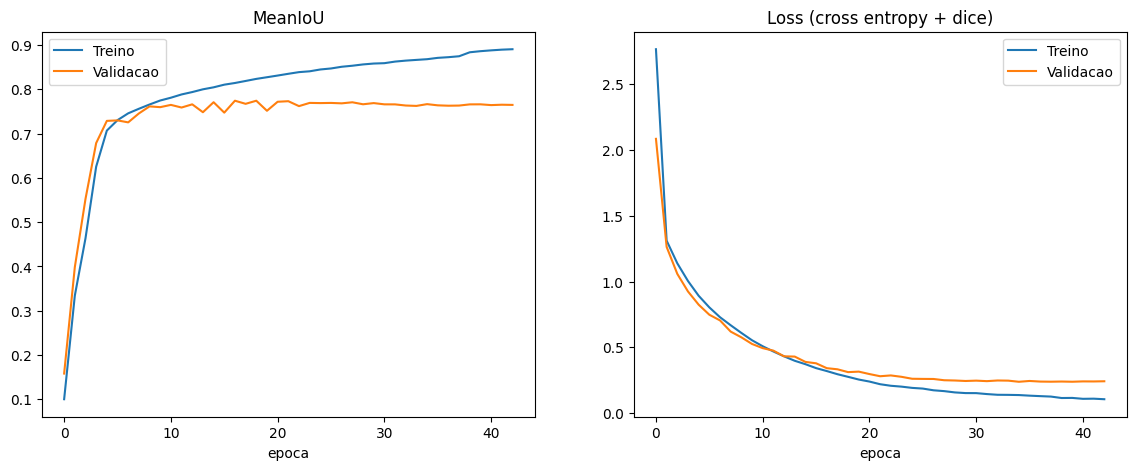

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(treino.history['mean_io_u'], label='Treino')
plt.plot(treino.history['val_mean_io_u'], label='Validacao')
plt.title('MeanIoU')
plt.xlabel('epoca')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(treino.history['loss'], label='Treino')
plt.plot(treino.history['val_loss'], label='Validacao')
plt.title('Loss (cross entropy + dice)')
plt.xlabel('epoca')
plt.legend()

plt.show()
